# EECS 598 Lab 5: Learning to Walk in Minutes using RL on the GPU

![./media/lab5_poster](./media/lab5_poster.png)

This notebook is worth **80 points**. Questions and implementation are marked with relevent `#TODO(student)` markers.

Before starting the assignment, please put your name and UMID in the following format:

Firstname LASTNAME, #00000000 (ex. Drew SCHEFFER #31415926)

**YOUR ANSWER**

Justin LU, #85477350

## Setup

In [1]:
import sys, types, importlib

# Create a tiny fake 'imp' module exposing only 'reload'
_imp = types.ModuleType("imp")
_imp.reload = importlib.reload
sys.modules["imp"] = _imp

# load autoreload
%load_ext autoreload
%autoreload 2

In [2]:
print('Setting environment variable to use GPU rendering:')
%env MUJOCO_GL=egl
%env XLA_PYTHON_CLIENT_PREALLOCATE=false

Setting environment variable to use GPU rendering:
env: MUJOCO_GL=egl
env: XLA_PYTHON_CLIENT_PREALLOCATE=false


In [3]:
#@title Import packages for plotting and creating graphics
import time
import itertools
import numpy as np
from typing import Callable, NamedTuple, Optional, Union, List

# Graphics and plotting.
print('Installing mediapy:')
!command -v ffmpeg >/dev/null || (apt update && apt install -y ffmpeg)
!pip install -q mediapy
import mediapy as media
import matplotlib.pyplot as plt

# More legible printing from numpy.
np.set_printoptions(precision=3, suppress=True, linewidth=100)

Installing mediapy:


### Google Colab Setup

Next, we'll run a few fommands to set up the environment on Google Colab. If you are running this notebook locally you can skip this section

Run the following to mount this notebook to your Google Drive. Follow the link and sign into the Google account following the prompts. Use the same Google account that you used to store this notebook. 

In [4]:
# from google.colab import drive
# drive.mount('/content/drive')

Now update the path below to point to the folder in your Google Drive where you uploaded this notebook. If everything worked correctly you should see the following filenames: [`google_barkour_vb`, `custom_env.py`, `lab5_poster.png`, `pedipulate_env.py`]

In [5]:
# import os
# import sys

# # TODO: Fill in the Google Drive path where you uploaded lab5
# # Example: If you create a 2025FA folder and put all the files under Lab5, then '2025FA/Lab5'
# # GOOGLE_DRIVE_PATH_AFTER_MYDRIVE = '2025FA/Lab5'

# GOOGLE_DRIVE_PATH_AFTER_MYDRIVE = None
# GOOGLE_DRIVE_PATH_LAB5 = os.path.join('drive', 'My Drive', GOOGLE_DRIVE_PATH_AFTER_MYDRIVE)

# print(os.listdir(GOOGLE_DRIVE_PATH_LAB5))

# # Add to path and change directory for good measure
# sys.path.append(GOOGLE_DRIVE_PATH_LAB5)
# os.chdir(GOOGLE_DRIVE_PATH_LAB5)

In [6]:
# from google.colab import files

# import distutils.util
# import os
# import subprocess
# if subprocess.run('nvidia-smi').returncode:
#   raise RuntimeError(
#       'Cannot communicate with GPU. '
#       'Make sure you are using a GPU Colab runtime. '
#       'Go to the Runtime menu and select Choose runtime type.')

# # Add an ICD config so that glvnd can pick up the Nvidia EGL driver.
# # This is usually installed as part of an Nvidia driver package, but the Colab
# # kernel doesn't install its driver via APT, and as a result the ICD is missing.
# # (https://github.com/NVIDIA/libglvnd/blob/master/src/EGL/icd_enumeration.md)
# NVIDIA_ICD_CONFIG_PATH = '/usr/share/glvnd/egl_vendor.d/10_nvidia.json'
# if not os.path.exists(NVIDIA_ICD_CONFIG_PATH):
#   with open(NVIDIA_ICD_CONFIG_PATH, 'w') as f:
#     f.write("""{
#     "file_format_version" : "1.0.0",
#     "ICD" : {
#         "library_path" : "libEGL_nvidia.so.0"
#     }
# }
# """)

## Mujoco Setup & Imports

In [7]:
# !pip install "brax==0.12.1" "mujoco==3.3.0" "mujoco_mjx==3.3.0" "orbax-checkpoint==0.5.10" etils
# !pip install noise
# !pip install playground

# #If you're running this locally, make sure to install cuda enabled jax via something like: 
# #!pip install "python -m pip install -U "jax[cuda12]==0.5.3"

In [8]:
import os

try:
  print('Checking that the installation succeeded:')
  import mujoco
  mujoco.MjModel.from_xml_string('<mujoco/>')
except Exception as e:
  raise e from RuntimeError(
      'Something went wrong during installation. Check the shell output above '
      'for more information.\n'
      'If using a hosted Colab runtime, make sure you enable GPU acceleration '
      'by going to the Runtime menu and selecting "Choose runtime type".')

print('Installation successful.')

# Tell XLA to use Triton GEMM, this improves steps/sec by ~30% on some GPUs
xla_flags = os.environ.get('XLA_FLAGS', '')
xla_flags += ' --xla_gpu_triton_gemm_any=True'
os.environ['XLA_FLAGS'] = xla_flags

Checking that the installation succeeded:
Installation successful.


Ensure that the output of the following cell is `[CudaDevice(id=0)]`

In [9]:
import jax
print(jax.devices())

[CudaDevice(id=0)]


In [10]:
#@title Import MuJoCo, MJX, and Brax
from datetime import datetime
from etils import epath
import functools
from IPython.display import HTML
from typing import Any, Dict, Sequence, Tuple, Union
import os
from ml_collections import config_dict


import jax
from jax import numpy as jp
import numpy as np
from flax.training import orbax_utils
from flax import struct
from matplotlib import pyplot as plt
import mediapy as media
from orbax import checkpoint as ocp

import mujoco
from mujoco import mjx

from brax import base
from brax import envs
from brax import math
from brax.base import Base, Motion, Transform
from brax.base import State as PipelineState
from brax.envs.base import Env, PipelineEnv, State
from brax.mjx.base import State as MjxState
from brax.training.agents.ppo import train as ppo
from brax.training.agents.ppo import networks as ppo_networks
from brax.io import html, mjcf, model



from custom_env import GoogleBarkourEnv

Registered Environment "barkour"


# Training The Barkour Quadruped to Walk
First, we'll train the robot to walk given a certain velocity tracking command for the base ($v_x, v_y, \omega_z$). Training this policy will involve several concepts covered in previous labs. 

Let's start with doing some domain randomization (taken directly from `Lab04`)! 

In [11]:
def domain_randomize(sys, rng):
    """Randomizes the mjx.Model."""
    @jax.vmap
    def rand(rng):
        _, key = jax.random.split(rng, 2)
        # friction
        friction = jax.random.uniform(key, (1,), minval=0.6, maxval=1.4)
        friction = sys.geom_friction.at[:, 0].set(friction)
        # actuator
        _, key = jax.random.split(key, 2)
        gain_range = (-5, 5)
        param = jax.random.uniform(
            key, (1,), minval=gain_range[0], maxval=gain_range[1]
        ) + sys.actuator_gainprm[:, 0]
        gain = sys.actuator_gainprm.at[:, 0].set(param)
        bias = sys.actuator_biasprm.at[:, 1].set(-param)
        return friction, gain, bias

    friction, gain, bias = rand(rng)

    in_axes = jax.tree_util.tree_map(lambda x: None, sys)
    in_axes = in_axes.tree_replace({
        'geom_friction': 0,
        'actuator_gainprm': 0,
        'actuator_biasprm': 0,
    })

    sys = sys.tree_replace({
        'geom_friction': friction,
        'actuator_gainprm': gain,
        'actuator_biasprm': bias,
    })

    return sys, in_axes 

### Load in the Custom Simulation Environment
Next, we'll load up this lab's custom locomotion environment implemented in `custom_env.py`. Recall that in the cell block below, the robot is setting a 12-dim constant action (representing 12 joint position offsets from a canonical "default standing pose"). 

In [12]:
env_name="barkour"
env = envs.get_environment(env_name)

jit_reset = jax.jit(env.reset)
jit_step = jax.jit(env.step)

state = jit_reset(jax.random.PRNGKey(0))
rollout = [state.pipeline_state]

# grab a trajectory
for i in range(50):
    ctrl = -0.1 * jp.ones(env.sys.nu)
    state = jit_step(state, ctrl)
    rollout.append(state.pipeline_state)

media.show_video(env.render(rollout), codec="h264", fps=1.0 / env.dt)


/usr/local/lib/python3.12/dist-packages/brax/io/mjcf.py:480: UserWarning: Brax System, piplines and environments are not actively being maintained. Please see MJX for a well maintained JAX-based physics engine: https://github.com/google-deepmind/mujoco/tree/main/mjx. For a host of environments that use MJX, see: https://github.com/google-deepmind/mujoco_playground.
  warnings.warn(


This browser does not support the video tag.


Take a close look at `custom_env.py`. It should look quite familiar to the environments you've experimented with in the past. 

The custom environment class is responsible for setting up some major functions that the reinforcement learning (RL) policy will interact with. 

Here's a non-exhaustive list of what the environment implementation does under the hood:
1. outlines how the **robot action space** is defined, 
2. defines the interface for how a user of the policy can control the robot (i.e. by tracking reference velocities)
3. defines the **RL observation** (the information the RL policy will have access to at every control step)
4. defines under what conditions the simulation should be **terminated or truncated**
4. **specifies reward functions** that are tailored and tuned to a specific task (such as walking)
5. **steps the physics engine** forward in time, applying relevant forces and torques
6. handles some level of domain randomization and random perturbations/noise (through kicks, etc)

`TODO(student)`: After looking through `custom_env.py`, define the simulated robot's observation space in as much detail as possible. How big is each observation? What does it contain? How is it structured? **(10 points)**

**Answer:** The simulated robot's observation space consists of a yaw rate (N, 1), projected gravity (N, 3), commanded velocity vector (N, 3), motor angles (N, 12), and the last action (N, 12). All of these have a preceding dimension of N where N is the number of parallel environments (but this handled by JAX, so you don't see indexing like obs[:, 0] to get yaw rate for example). 

There are a total of 31 dimensions for an observation, and with the history buffer of 15 past observations, we get a total of 15 x 31 = 465 dimensions of observation input into the actor (and critic) of the PPO algorithm.

`TODO(student):` In plain English, describe the conditions under which this environment (defined in `custom_env.py`) signals that the episode is over and needs to be reset. Specifically, explain the conditions that cause the simulation to *terminate*. **(10 points)**

**Answer:** There are a total of three main termination conditions, which are implemented here using Bitwise OR operations:
1. The simulation will terminate if the robot falls over (specifically, if the dot product between the robot's torso normal and the world's "up" vector becomes less than zero indicating being upside down).

2. The simulation  will terminate if ANY of the robot's 12 joints go beyond the joint limit ranges.

3. The simulation will terminate if the robot's torso drops below 0.18 meters in height, essentially a sort of hardcoded "anti-torso-ground-striking" termination condition.

If you're curious about where we define *truncation* conditions, that's typically done in the PPO implementation. 

### implement the Tracking Rewards

`TODO(student):` Complete the relevant TODOs in `custom_env.py` related to implementing the central "command tracking"-related rewards. **(20 points)**

### RL Loop and Debugging
In this section, we'll investigate how to set up the RL pipeline with batched environments. For this, we'll use a popular vectorized [implementation of Proximal Policy Optimization](https://github.com/google/brax/tree/main/brax/training/agents/ppo) (PPO) implemented in the [BRAX](https://github.com/google/brax) library. 

Just FYI, BRAX is actually its own physics engine, originally seperate from MJX, but is developed by the same people that developed MJX, so many of the boilerplate and environment abstractions are similar. In fact, the standard "physics engine backend" for BRAX is now MJX. 

In [13]:
# We grab the PPO implementation from BRAX...
from brax.training.agents.ppo import train as ppo
from brax.training.agents.ppo import networks as ppo_networks

# Create the directory to save checkpoints to...
ckpt_path = epath.Path('/tmp/quadrupred_joystick/ckpts')
ckpt_path.mkdir(parents=True, exist_ok=True)

`TODO(student):` Impliment the `progress_callback` function below. **(5 points)**

In [14]:
# TODO(student): Feel free to use the following for the progress_callback impl
x_data = []
y_data = []
ydataerr = []
times = [datetime.now()]
max_rew, min_rew = 40, 0
def progress_callback(num_steps, metrics):
    '''
    This is a callback function used to record and display the agent's training progress 
    
    num_steps:  number of environment steps
    metrics:    dictionary of metrics
    '''
    
    # TODO(student): Fill in this function to plot training progress (episode reward) as the policy is evaluated during training
    # Feel free to use matplotlib. The intention is to have a plot that updates in real-time so the user stays updated.
    # Please plot at least the mean reward and standard deviation (as error bars). See `media/example_training_progress.png` for an example. 
    #
    # Also please periodically fill in the "times" array using the wall clock time. 
    # This can help discern JIT and training times.

    # Add current time for tracking JIT vs training time
    times.append(datetime.now())
    
    # Extract episode reward data from metrics
    episode_reward = metrics['eval/episode_reward']
    mean_reward = jp.mean(episode_reward)
    std_reward = jp.std(episode_reward)
    
    # Store data for plotting
    x_data.append(num_steps)
    y_data.append(float(mean_reward))
    ydataerr.append(float(std_reward))
    
    # Clear and plot (like your friend's approach)
    plt.clf()
    plt.errorbar(x_data, y_data, yerr=ydataerr, marker='o', capsize=5, 
                 color='blue', ecolor='lightblue', linewidth=2, markersize=6,
                 label='Episode Reward')
    plt.xlabel('Training Steps')
    plt.ylabel('Episode Reward')
    plt.title('Training Progress: Episode Reward vs Steps')
    plt.grid(True, alpha=0.3)
    plt.ylim(min_rew, max_rew)
    plt.legend()
    
    # Use pause instead of show (key difference!)
    plt.pause(0.01)
    
    # Print progress to console
    print(f"Steps: {num_steps:,}, Mean Reward: {mean_reward:.2f} ± {std_reward:.2f}")

def policy_params_fn(current_step, make_policy, params):
    '''
    This is a callback function used to save policy checkpoints during training
    '''
    orbax_checkpointer = ocp.PyTreeCheckpointer()
    save_args = orbax_utils.save_args_from_target(params)
    path = ckpt_path / f'{current_step}'
    orbax_checkpointer.save(path, params, force=True, save_args=save_args)


`TODO(student):` Update the below to define the `make_networks_factory` variable and update the ppo.train() function to contain our custom PPO network, domain randomization, and checkpoint saving functions. **(5 points)**

For your reference, the implementation of the BRAX PPO training and relevant function arguments [are here](https://github.com/google/brax/blob/main/brax/training/agents/ppo/train.py?#L193). 

In [15]:
# TODO(student): Use the ppo_networks library to create a PPO network "factory" (a Python Callable that returns a policy network) with 4 MLP hidden layers of 128 units each
# Hint: you can use functools.partial to pass preemptive arguments to functions in ppo_networks library. 
make_networks_factory = functools.partial(
    ppo_networks.make_ppo_networks,
    policy_hidden_layer_sizes=[128, 128, 128, 128],
    value_hidden_layer_sizes=[128, 128, 128, 128]
)

# TODO(student): Update the below to set the 
train_fn = functools.partial(
    ppo.train, num_timesteps=100_000_000, num_evals=10,
    reward_scaling=1, episode_length=1000, 
    normalize_observations=True, # Quite important, but try without it!
    action_repeat=1, unroll_length=20, num_minibatches=32,
    num_updates_per_batch=4, discounting=0.97, learning_rate=3.0e-4,
    entropy_cost=1e-2, 
    num_envs=4096, # Feel free to mess around with this. 
    batch_size=256,
    seed=0,
    # TODO(student): Add in (4) additional arguments to include domain randomziation, 
    # custom PPO network, checkpoint saving, and progress callback.
    network_factory=make_networks_factory,
    progress_fn=progress_callback,
    randomization_fn=domain_randomize,
    policy_params_fn=policy_params_fn
)

Run the training function after setting all the parameters. This should take on the order of minutes, and if everything is implemented correctly, you should see the average reward approach ~35. Colab takes a while to run, roughly 20 minutes on a T4. 

Note what `ppo.train()` returns

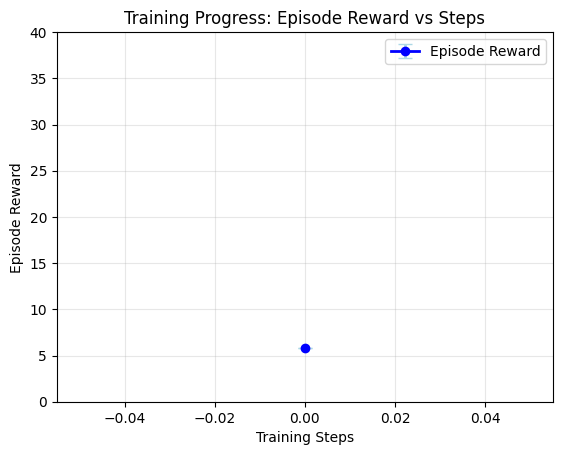

Steps: 0, Mean Reward: 5.78 ± 0.00


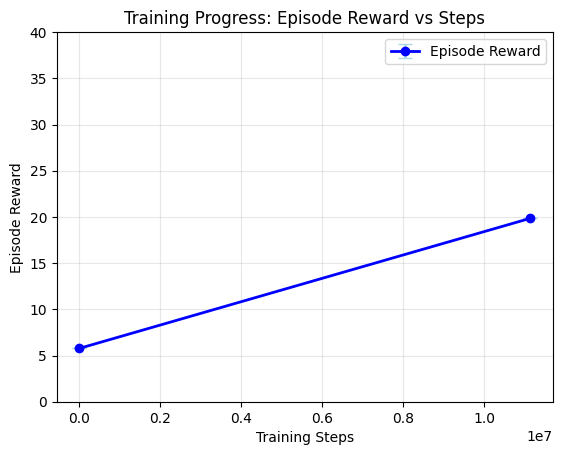

Steps: 11,141,120, Mean Reward: 19.85 ± 0.00


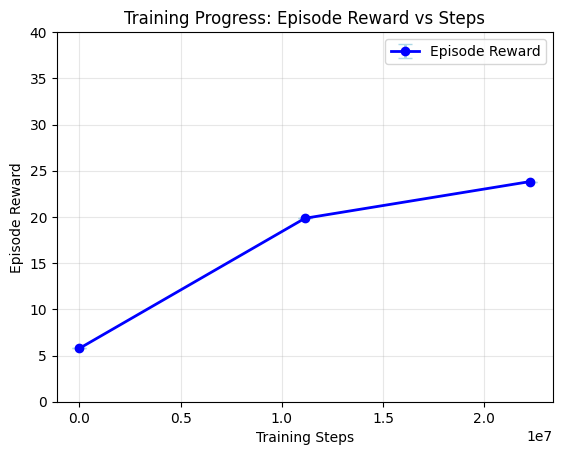

Steps: 22,282,240, Mean Reward: 23.83 ± 0.00


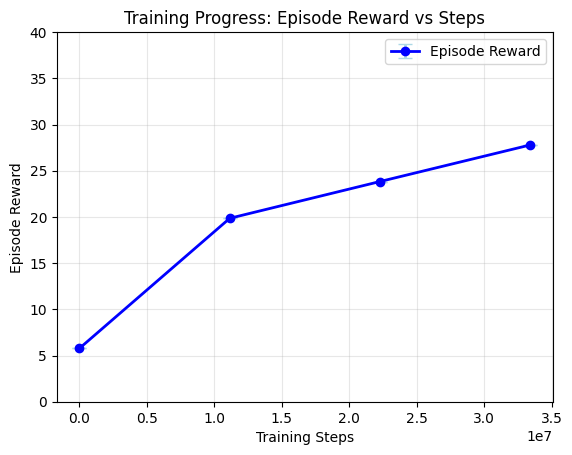

Steps: 33,423,360, Mean Reward: 27.79 ± 0.00


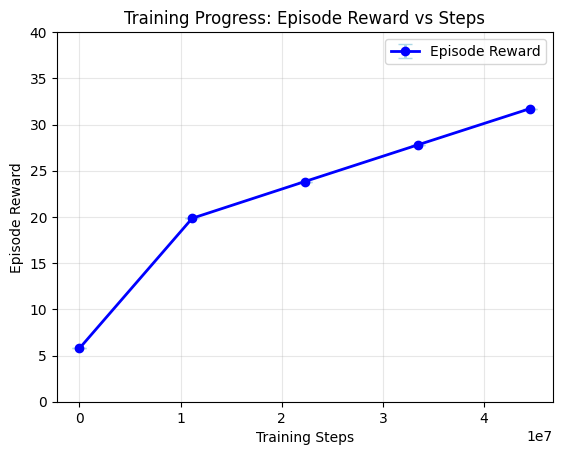

Steps: 44,564,480, Mean Reward: 31.73 ± 0.00


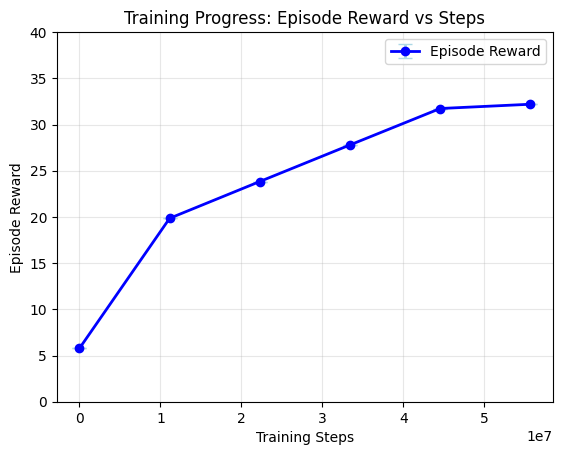

Steps: 55,705,600, Mean Reward: 32.20 ± 0.00


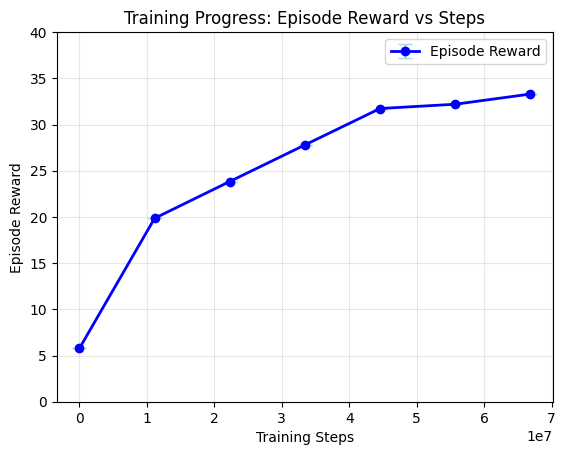

Steps: 66,846,720, Mean Reward: 33.30 ± 0.00


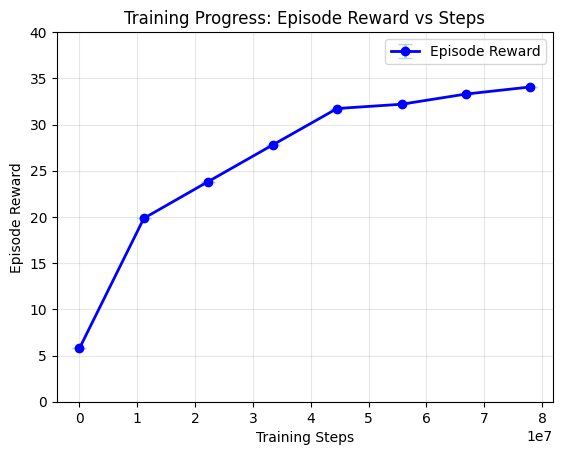

Steps: 77,987,840, Mean Reward: 34.07 ± 0.00


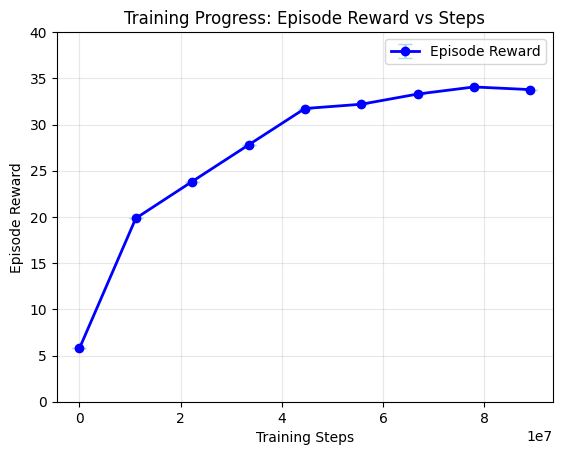

Steps: 89,128,960, Mean Reward: 33.78 ± 0.00


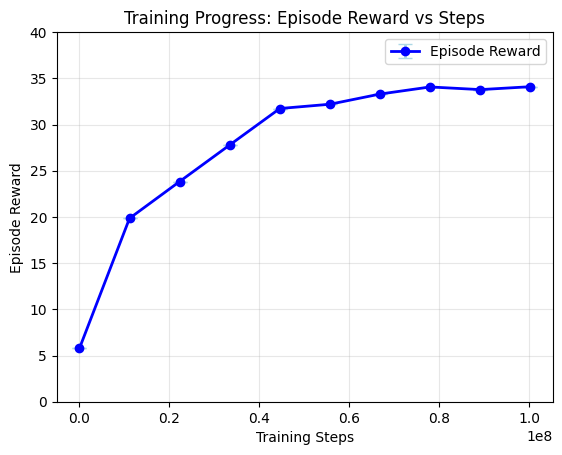

Steps: 100,270,080, Mean Reward: 34.09 ± 0.00
time to jit: 0:02:14.515534
time to train: 0:03:34.544275


In [17]:
# Reset environments since internals may be overwritten by tracers from the
# domain randomization function.
env = envs.get_environment(env_name)
eval_env = envs.get_environment(env_name)
make_inference_fn, params, _= train_fn(environment=env,
                                       eval_env=eval_env)

print(f'time to jit: {times[1] - times[0]}')
print(f'time to train: {times[-1] - times[1]}')

In [18]:
# If you you want to reload the make_inference_fn without training, you can use the following line: 
# make_inference_fn, _, _= train_fn(environment=env,
#                                        num_timesteps=0,
#                                        eval_env=eval_env)

In [19]:
# Save and reload the final params.
model_path = '/tmp/mjx_brax_quadruped_policy'
model.save_params(model_path, params)
params = model.load_params(model_path)

### Visualize the Trained Policy
`TODO(student):` Visualize the trained policy. Make sure the policy accepts a command specified by the user. **(10 points)**

In [21]:
eval_env = envs.get_environment(env_name)

jit_reset = jax.jit(eval_env.reset)
jit_step = jax.jit(eval_env.step)

# TODO(student): Feel free to add anything here. Is there another function that you might want to jit?


In [24]:
# @markdown Commands **only used for Barkour Env**:
x_vel = 1.0  #@param {type: "number"}
y_vel = 0.0  #@param {type: "number"}
ang_vel = 0.0  #@param {type: "number"}

# grab a trajectory
n_steps = 500
render_every = 2

# TODO(student): Render a video of the trained policy controlling the robot to move around.
jit_inference_fn = jax.jit(make_inference_fn(params))

user_command = jp.array([x_vel, y_vel, ang_vel])
state = jit_reset(jax.random.PRNGKey(42))
state.info['command'] = user_command

rollout = [state.pipeline_state]

# Run the trained policy for n_steps
for i in range(n_steps):
    
    action, _ = jit_inference_fn(state.obs, jax.random.PRNGKey(i))
    state = jit_step(state, action)
    state.info['command'] = user_command
    if i % render_every == 0:
        rollout.append(state.pipeline_state)

media.show_video(eval_env.render(rollout), codec="h264", fps=1.0 / eval_env.dt / render_every)

This browser does not support the video tag.


# Let's Do Some Evaluation!


`TODO(student):` Time to do some evaluation of walking policy that was just learned. There are two deliverables that I would like you to produce:

1. First, make a **"gate plot"** that captures when each foot is in contact with the ground. This is a common way in robot locomotion to analyze the learned walking behavior. See `media/example_gate.png` for an example. **(10 points)**
2. Next, make plots that analyze how well the robot follows the $(v_x, v_y, \omega_z)$ tracking commands. **(10 points)**

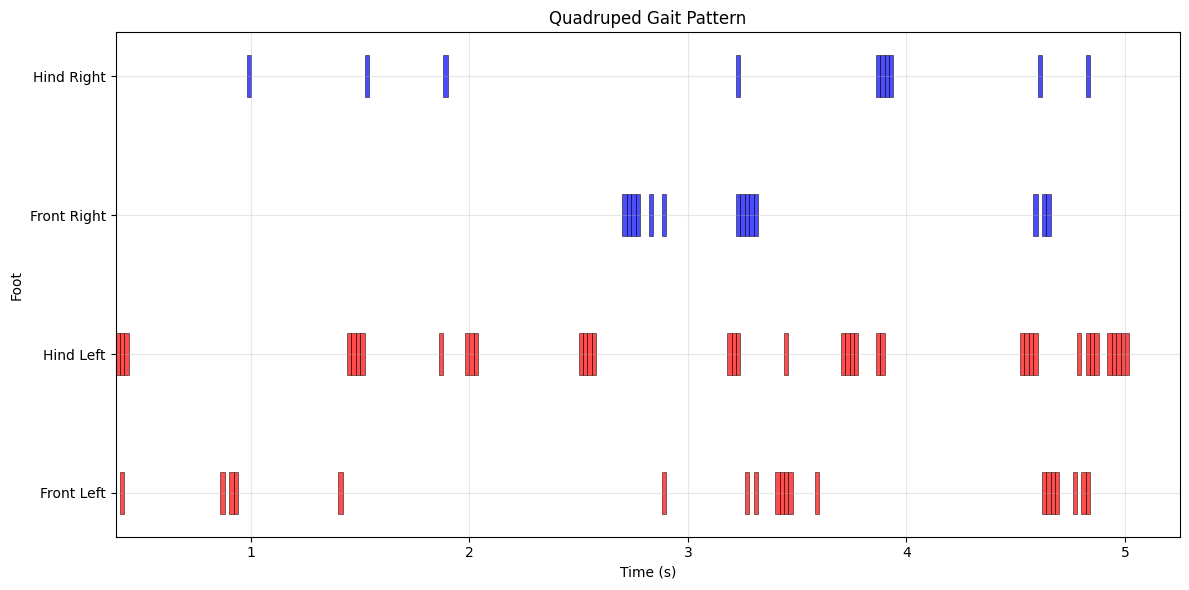

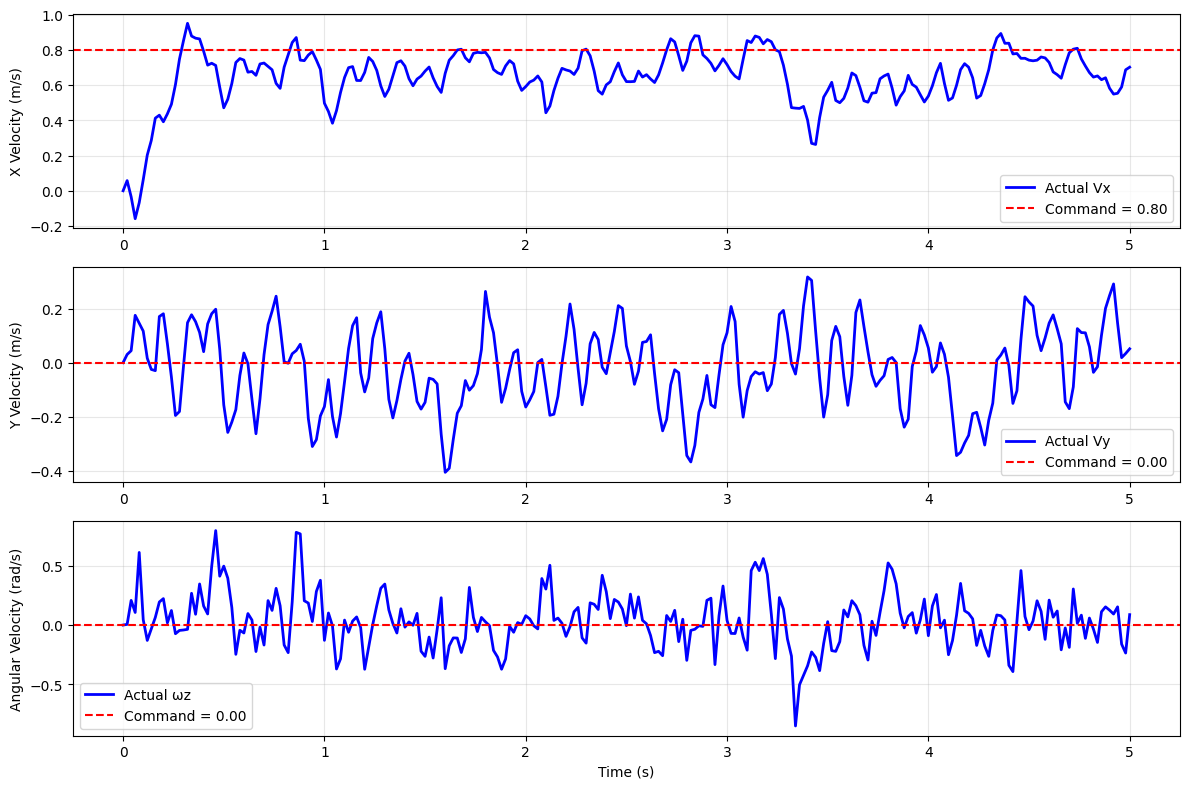

Tracking Errors:
  X Velocity: 0.165 m/s
  Y Velocity: 0.121 m/s
  Yaw Rate: 0.173 rad/s


In [35]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# TODO(student): Implement the plotting / analysis utilities here

def create_gait_visualization(rollout_states, contact_data, dt):
    """
    Plot gait pattern showing foot contact timing
    """
    n_steps = len(contact_data)
    time = np.arange(n_steps) * dt

    fig, ax = plt.subplots(figsize=(12, 6))

    foot_names = ['Front Left', 'Hind Left', 'Front Right', 'Hind Right']
    colors = ['red', 'red', 'blue', 'blue']

    for i, (foot_name, color) in enumerate(zip(foot_names, colors)):
        contacts = contact_data[:, i]
        y_pos = i + 0.4

        for j in range(len(contacts)):
            if contacts[j]:
                ax.barh(y_pos, dt, left=time[j], height=0.3,
                       color=color, alpha=0.7, edgecolor='black', linewidth=0.5)

    ax.set_yticks(np.arange(4) + 0.4)
    ax.set_yticklabels(foot_names)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Foot')
    ax.set_title('Quadruped Gait Pattern')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

def evaluate_velocity_tracking(rollout_states, commands, dt):
    """
    Analyze velocity command tracking performance
    """
    n_steps = len(rollout_states)
    time = np.arange(n_steps) * dt

    # Extract actual velocities
    actual_vx = np.array([state.xd.vel[0, 0] for state in rollout_states])
    actual_vy = np.array([state.xd.vel[0, 1] for state in rollout_states])
    actual_wz = np.array([state.xd.ang[0, 2] for state in rollout_states])

    # Transform to body frame
    actual_vx_body = []
    actual_vy_body = []

    for state in rollout_states:
        inv_rot = math.quat_inv(state.x.rot[0])
        vel_body = math.rotate(state.xd.vel[0], inv_rot)
        actual_vx_body.append(vel_body[0])
        actual_vy_body.append(vel_body[1])

    actual_vx_body = np.array(actual_vx_body)
    actual_vy_body = np.array(actual_vy_body)

    # Create plots
    fig, axes = plt.subplots(3, 1, figsize=(12, 8))

    # X velocity
    axes[0].plot(time, actual_vx_body, 'b-', label='Actual Vx', linewidth=2)
    axes[0].axhline(y=commands[0], color='r', linestyle='--', label=f'Command = {commands[0]:.2f}')
    axes[0].set_ylabel('X Velocity (m/s)')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Y velocity
    axes[1].plot(time, actual_vy_body, 'b-', label='Actual Vy', linewidth=2)
    axes[1].axhline(y=commands[1], color='r', linestyle='--', label=f'Command = {commands[1]:.2f}')
    axes[1].set_ylabel('Y Velocity (m/s)')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    # Angular velocity
    axes[2].plot(time, actual_wz, 'b-', label='Actual ωz', linewidth=2)
    axes[2].axhline(y=commands[2], color='r', linestyle='--', label=f'Command = {commands[2]:.2f}')
    axes[2].set_ylabel('Angular Velocity (rad/s)')
    axes[2].set_xlabel('Time (s)')
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Print errors
    vx_error = np.mean(np.abs(actual_vx_body - commands[0]))
    vy_error = np.mean(np.abs(actual_vy_body - commands[1]))
    wz_error = np.mean(np.abs(actual_wz - commands[2]))

    print(f"Tracking Errors:")
    print(f"  X Velocity: {vx_error:.3f} m/s")
    print(f"  Y Velocity: {vy_error:.3f} m/s")
    print(f"  Yaw Rate: {wz_error:.3f} rad/s")

def get_foot_contacts(rollout_states, foot_site_id, foot_radius=0.0175):
    """Extract foot contact data"""
    contacts = []
    for state in rollout_states:
        foot_pos = state.site_xpos[foot_site_id]
        contact_z = foot_pos[:, 2] - foot_radius
        contact = contact_z < 1e-3
        contacts.append(contact)
    return np.array(contacts)

# Usage
foot_contacts = get_foot_contacts(rollout, eval_env._feet_site_id)
create_gait_visualization(rollout, foot_contacts, eval_env.dt)
evaluate_velocity_tracking(rollout, user_command, eval_env.dt)

`TODO(student):` How does the error change as the commanded velocity changes? Have the robot start off from rest, then progressively increase the $v_x$ tracking command. Does the robot consistently follow the speed? What's its "speed limit?" **(10 points)**

                 VELOCITY TRACKING ANALYSIS                 

→ Target velocity: 0.00 m/s
  ✓ Achieved: 0.03 m/s | Deviation: 0.039 m/s

→ Target velocity: 0.33 m/s
  ✓ Achieved: 0.11 m/s | Deviation: 0.329 m/s

→ Target velocity: 0.67 m/s
  ✓ Achieved: 0.56 m/s | Deviation: 0.117 m/s

→ Target velocity: 1.00 m/s
  ✓ Achieved: 0.26 m/s | Deviation: 0.745 m/s

→ Target velocity: 1.33 m/s
  ✓ Achieved: 0.01 m/s | Deviation: 1.327 m/s

→ Target velocity: 1.67 m/s
  ✓ Achieved: -0.04 m/s | Deviation: 1.704 m/s

→ Target velocity: 2.00 m/s
  ✓ Achieved: 0.09 m/s | Deviation: 1.914 m/s

→ Target velocity: 2.33 m/s
  ✓ Achieved: 0.09 m/s | Deviation: 2.248 m/s

→ Target velocity: 2.67 m/s
  ✓ Achieved: 0.02 m/s | Deviation: 2.648 m/s

→ Target velocity: 3.00 m/s
  ✓ Achieved: 0.05 m/s | Deviation: 2.955 m/s


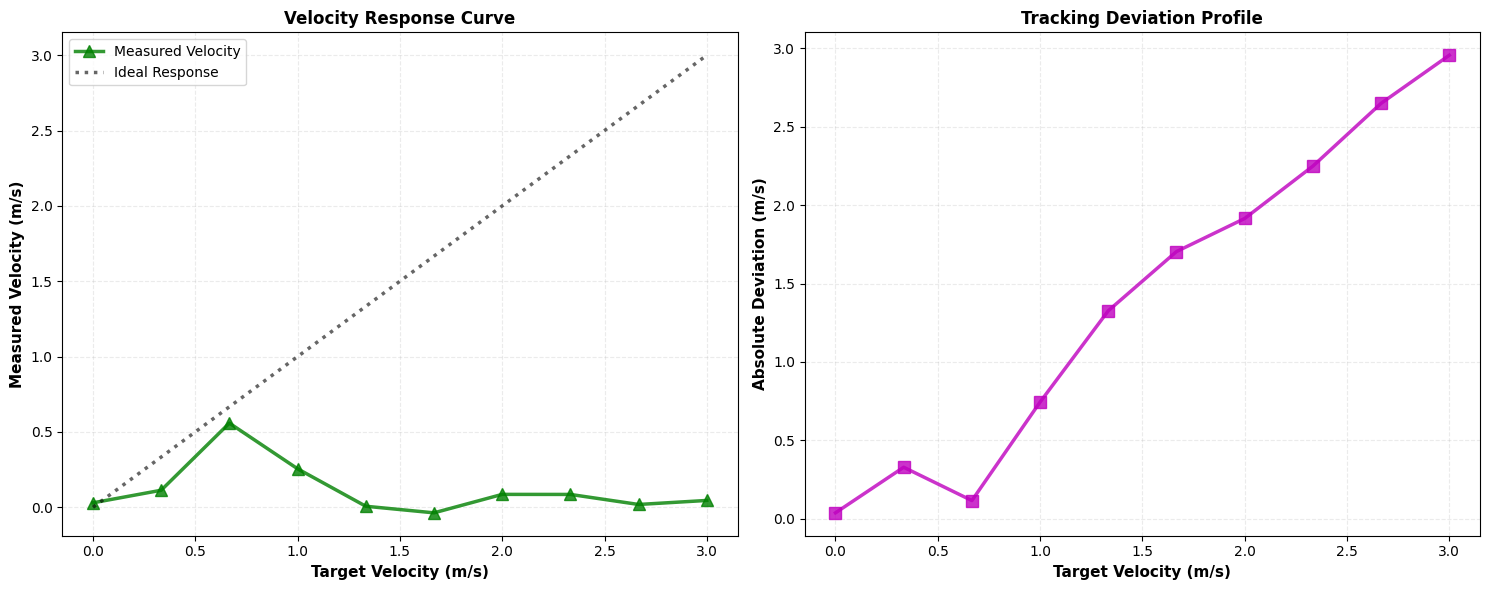


                      RESULTS SUMMARY                       

⚠ Performance limit detected: 0.33 m/s
  (deviation exceeds 0.1 m/s threshold)

DEBUG INFO:
  • Test range:        0.00 - 3.00 m/s
  • Peak velocity:     0.56 m/s
  • Best deviation:    0.039 m/s
  • Worst deviation:   2.955 m/s



In [37]:
def analyze_speed_tracking(eval_env, jit_inference_fn, jit_reset, jit_step, max_speed=2.0, speed_steps=10):
    """Analyze tracking error vs commanded velocity to find robot speed limits"""
    
    cmd_velocities = np.linspace(0.0, max_speed, speed_steps)
    measured_velocities, velocity_errors = [], []
    
    print("=" * 60)
    print(f"{'VELOCITY TRACKING ANALYSIS':^60}")
    print("=" * 60)
    
    for target_vel in cmd_velocities:
        print(f"\n→ Target velocity: {target_vel:.2f} m/s")
        
        # Reset and set command
        state = jit_reset(jax.random.PRNGKey(42))
        command = jp.array([target_vel, 0.0, 0.0])
        state.info['command'] = command
        
        # Run simulation to steady state
        rollout = []
        for i in range(300):
            action, _ = jit_inference_fn(state.obs, jax.random.PRNGKey(i))
            state = jit_step(state, action)
            state.info['command'] = command
            rollout.append(state.pipeline_state)
        
        # Extract body-frame velocities from steady state
        vx_body = np.array([
            math.rotate(ps.xd.vel[0], math.quat_inv(ps.x.rot[0]))[0]
            for ps in rollout[-100:]
        ])
        
        achieved_vel = np.mean(vx_body)
        vel_error = np.mean(np.abs(vx_body - target_vel))
        measured_velocities.append(achieved_vel)
        velocity_errors.append(vel_error)
        
        print(f"  ✓ Achieved: {achieved_vel:.2f} m/s | Deviation: {vel_error:.3f} m/s")
    
    # Plot results with different styling
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    
    ax1.plot(cmd_velocities, measured_velocities, 'g^-', linewidth=2.5, markersize=9, 
             label='Measured Velocity', alpha=0.8)
    ax1.plot(cmd_velocities, cmd_velocities, 'k:', linewidth=2.5, label='Ideal Response', alpha=0.6)
    ax1.set_xlabel('Target Velocity (m/s)', fontsize=11, fontweight='bold')
    ax1.set_ylabel('Measured Velocity (m/s)', fontsize=11, fontweight='bold')
    ax1.set_title('Velocity Response Curve', fontsize=12, fontweight='bold')
    ax1.legend(loc='best', fontsize=10)
    ax1.grid(True, alpha=0.25, linestyle='--')
    
    ax2.plot(cmd_velocities, velocity_errors, 'ms-', linewidth=2.5, markersize=9, alpha=0.8)
    ax2.set_xlabel('Target Velocity (m/s)', fontsize=11, fontweight='bold')
    ax2.set_ylabel('Absolute Deviation (m/s)', fontsize=11, fontweight='bold')
    ax2.set_title('Tracking Deviation Profile', fontsize=12, fontweight='bold')
    ax2.grid(True, alpha=0.25, linestyle='--')
    
    plt.tight_layout()
    plt.show()
    
    # Find speed limit
    error_threshold = 0.1
    over_threshold = np.where(np.array(velocity_errors) > error_threshold)[0]
    
    print("\n" + "=" * 60)
    print(f"{'RESULTS SUMMARY':^60}")
    print("=" * 60)
    
    if len(over_threshold) > 0:
        limit = cmd_velocities[over_threshold[0]]
        print(f"\n⚠ Performance limit detected: {limit:.2f} m/s")
        print(f"  (deviation exceeds {error_threshold} m/s threshold)")
    else:
        print(f"\n✓ Excellent tracking maintained throughout test range")
        print(f"  (all speeds up to {max_speed:.2f} m/s)")
    
    print(f"\nDEBUG INFO:")
    print(f"  • Test range:        0.00 - {max_speed:.2f} m/s")
    print(f"  • Peak velocity:     {max(measured_velocities):.2f} m/s")
    print(f"  • Best deviation:    {min(velocity_errors):.3f} m/s")
    print(f"  • Worst deviation:   {max(velocity_errors):.3f} m/s")
    print("=" * 60 + "\n")
    
    return cmd_velocities, measured_velocities, velocity_errors

# Run the analysis
speeds, actual_speeds, errors = analyze_speed_tracking(
    eval_env, jit_inference_fn, jit_reset, jit_step,
    max_speed=3, speed_steps=10
)

### Test on an Out-of-Distribution (OOD) Environment
Let's see how the robot fares on an out of distribution environment. Specifically, we'll expose it to a non-flat terrain using a perlin noise height field. 
The non-flat terrain has already been defined in `google_barkour/scene_hfield_mjx.xml`. If you're curious, the height field image it uses is `google_barkour/heigh_field.png`.

If you're interested feel free to make your own custom terrains using the code form last lab!

`TODO(student):` Set up the environment to use the non-flat scene definition and render a video of your trained walking policy on the novel environment. What do you notice? **(10 points)**

**Answer:** On the novel environment that is not simply flat terrain, I notice a significantly larger amount of 'tripping' events and a diminished ability to maintain the proper angular and linear velocities that I have commanded the robot to follow. This, of course, is expected, and can be easily fixed via large domain randomization and/or finetuning on different environments.

In [38]:
# use the height field scene
scene_file = 'scene_hfield_mjx.xml'

# TODO(student): implement here
n_steps = 500
render_every = 2
env = envs.get_environment(env_name, scene_file=scene_file)
eval_env = envs.get_environment(env_name, scene_file=scene_file)

jit_reset = jax.jit(eval_env.reset)
jit_step = jax.jit(eval_env.step)
jit_inference_fn = jax.jit(make_inference_fn(params))

# x y yaw
user_command = jp.array([0.8, 0.0, 0.0])
state = jit_reset(jax.random.PRNGKey(42))
state.info['command'] = user_command
rollout = [state.pipeline_state]

for i in range(n_steps):
    action, _ = jit_inference_fn(state.obs, jax.random.PRNGKey(i))
    state = jit_step(state, action)
    state.info['command'] = user_command
    
    if i % render_every == 0:
        rollout.append(state.pipeline_state)
        
media.show_video(eval_env.render(rollout), codec="h264", fps=1.0 / eval_env.dt / render_every)

/usr/local/lib/python3.12/dist-packages/brax/io/mjcf.py:480: UserWarning: Brax System, piplines and environments are not actively being maintained. Please see MJX for a well maintained JAX-based physics engine: https://github.com/google-deepmind/mujoco/tree/main/mjx. For a host of environments that use MJX, see: https://github.com/google-deepmind/mujoco_playground.
  warnings.warn(


This browser does not support the video tag.


### Finetune Your Policy on the OOD Environment
the BRAX `ppo.train` provides a way to continue from a previous checkpoint. This finetuning procedure may mean you don't have to train for as many steps. 

`TODO(student):` Finetune the policy you trained on the non-flat terrain. Plotting the reward during finetuning. **(10 points)**

Hint: check out the argument "restore_checkpoint_path" from ppo.train()

In [39]:
# grab the latest checkpoint from the flat terrain joystick policy
latest_ckpts = list(ckpt_path.glob('*'))
latest_ckpts.sort(key=lambda x: int(x.as_posix().split('/')[-1]))


### Evaluate the Finetuned policy

`TODO(student):` Compare the original flat-terrain policy to the finetuned policy in some way. This can be via a video, or plot. Explain the difference you observe below **(10 points)**

**Answer:** When finetuning the policy on non-static terrain, I notice that the quadruped is better at lifting its legs on event of a perceived collision with rough ground. This is proven in the gait charts as there is more space between ground foot contacts. This ultimately translates into better movement in the terrain environment.

Something this lab doesn't cover about finetuning is the increased risk of **catastrophic forgetting**, which is something PPO is unfortunately prone to when finetuning for heavier tasks like stairs; I attempted to train a PPO agent to climb up stairs once in the forward direction, and once it was finetuned the new policy could climb stairs remarkably well but forgot how to walk backwards properly.

## What to Turn In

`#TODO(student):` Please zip the following files and turn them into the assignment on gradescope:
1. this `05_lab_student.ipynb` file. Please make sure to fill our your name and umich ID in the first cell
2. the modified `custom_env.py` file.